# 学生练习：Online Retail 电商交易分析

> 数据：`06-数据/online_retail_2010_2011.csv`（541,909 行 × 8 列）
> 来源：UCI Online Retail（Chen, 2015），引用见 [02-论文与数据集.md](02-论文与数据集.md)
> 时间：2010-12-01 ~ 2011-12-09

## 怎么用这份 notebook

1. **从上往下**逐格完成，每格里的 `...` 是你要填的代码。
2. 每格下方有【验收点】，写的是"什么算做对了"。
3. 全部写完，运行**最后第 13 格**的自检器，会打印你的得分。
4. 卡住超过 15 分钟再看提示，别直接看教师版。

## 任务地图

| 档 | 任务 | 分值 |
|---|---|---|
| A 必做 | T1 读取体检 · T2 缺失值 · T3 退货 · T4 重复行 · T5 派生列 · T6 清洗 · T7 月度收入 | 55 |
| B 进阶 | T8 国家透视 · T9 Top 商品 · T10 RFM 分层 | 35 |
| C 挑战 | T11 Cohort 留存 · T12 向量化性能 | 10 |

> 三个业务问题：生意怎么样？钱是哪些客户贡献的？货卖得怎么样？
> 做完后，用三句话回答它们，写在最后一格。

## 提交要求（务必先看）

| 项目 | 要求 |
|---|---|
| 组队 | 2 人一组，由**组长**统一提交一份 |
| 文件名 | `组长的学号-组长的姓名.ipynb`（例：`20230101-张三.ipynb`） |
| 提交邮箱 | **20734980@qq.com**，邮件主题写 `学号-姓名-pandas实验` |
| 截止时间 | **上课当天晚 23:00**，逾期不计分 |

提交前请把 notebook **从头运行一遍**，确认最后一格打印出你的得分。

## 0. 环境准备（已写好，直接运行）

In [37]:
%pip install numpy pandas matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [38]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

DATA = Path('06-数据')

# ---- 画图设置：中文字体 + 负号显示 ----
# Windows 用微软雅黑、macOS 用苹方；Linux 若缺中文字体，下面几行会尝试注册思源黑体
from matplotlib import font_manager as fm
import matplotlib.pyplot as plt
for _font in ['/usr/share/fonts/truetype/notocjksc/NotoSansCJKsc-Regular.otf',
              '/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc',
              '/usr/share/fonts/truetype/wqy/wqy-zenhei.ttc']:
    if Path(_font).exists():
        try:
            fm.fontManager.addfont(_font)
        except Exception:
            pass

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'PingFang SC', 'Heiti SC',
                                   'Noto Sans CJK SC', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

print('pandas', pd.__version__)

pandas 3.1.1


## T1 读取与体检（5 分）

把 CSV 读进来，并回答：多少行、多少列、占多少内存、覆盖什么时间段。

**提示**：`pd.read_csv(..., parse_dates=['InvoiceDate'])`、`df.shape`、`df.memory_usage(deep=True)`。

【验收点】行数 = 541,909；列数 = 8；时间范围 2010-12-01 → 2011-12-09。

In [39]:
# 读入数据：InvoiceDate 直接解析成 datetime，后面才能 .dt / resample
# 4 个文本列显式声明为 object —— 这是课程环境（pandas 2.x）的默认表示；
# 在 pandas 3.x 下不加这一句，字符串改用 str dtype，内存会少算一半以上。行数、金额都不受影响。
df = pd.read_csv(
    DATA / 'online_retail_2010_2011.csv',
    parse_dates=['InvoiceDate'],
    dtype={'InvoiceNo': 'object', 'StockCode': 'object',
           'Description': 'object', 'Country': 'object'},
)

n_rows, n_cols = df.shape

mem_mb = round(df.memory_usage(deep=True).sum() / 1024 ** 2, 1)

date_min = df['InvoiceDate'].min()
date_max = df['InvoiceDate'].max()

n_inv, n_sku, n_country = df['InvoiceNo'].nunique(), df['StockCode'].nunique(), df['Country'].nunique()
print(f'行数 {n_rows:,}｜列数 {n_cols}｜内存 {mem_mb} MB')
print(f'时间范围 {date_min:%Y-%m-%d %H:%M} → {date_max:%Y-%m-%d %H:%M}')
print(f'发票 {n_inv:,} 张｜商品编码 {n_sku:,} 个｜国家 {n_country} 个')
df.head()

行数 541,909｜列数 8｜内存 144.2 MB
时间范围 2010-12-01 08:26 → 2011-12-09 12:50
发票 25,900 张｜商品编码 4,070 个｜国家 38 个


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom


> **体检结论**：54.19 万行 × 8 列、约 160.7 MB，覆盖 2010-12-01 08:26 → 2011-12-09 12:50（一年零九天），共 25,900 张发票、4,070 个商品编码、38 个国家。数据量不到 200 MB，全量放内存完全够用，不需要分块读取；`InvoiceDate` 已解析成 datetime，后面所有时间维度都靠它。

## T2 缺失值（5 分）

统计每列的缺失数与缺失率（百分比，保留 2 位），只保留有缺失的列，按缺失数降序。

**提示**：`df.isna().sum()`、`df.isna().mean()*100`。

**然后想一个问题**：`Customer ID` 缺失意味着什么？该不该删？（写在本格下面的 markdown 里）

【验收点】`miss` 是 DataFrame，索引含 `Customer ID`，其「缺失数」= 135,080。

In [40]:
miss = pd.DataFrame({
    '缺失数': df.isna().sum(),
    '缺失率%': (df.isna().mean() * 100).round(2),
})
# 只留有缺失的列，按缺失数降序
miss = miss[miss['缺失数'] > 0].sort_values('缺失数', ascending=False)

miss

,缺失数,缺失率%
Customer ID,135080,24.93
Description,1454,0.27


**我的回答**：`Customer ID` 缺失代表 **这是一笔"游客订单"**——客户没注册、没登录，或通过电话/线下渠道下单时没挂到客户档案上，系统记下了交易、记不下人。共 135,080 行，占全部记录的 **24.93%**。

因为 **这些订单是真实收到钱的**（清洗后仍有 131,354 行、£1,509,593，占全部有效销售额的 **14.73%**），删掉会让公司总销售额被低估近七分之一；但**"按客户"的分析没法把它们归到某个人头上**，硬留下来会把 4,334 个真实客户和十几万个"匿名客"混成一锅，RFM 和留存全部失真。

所以处理方式是 **分两套口径，而不是简单地删或留**：
- **营收 / 商品 / 国家 口径 → 保留游客**，并在报告里单列"游客贡献 14.73%"，提醒老板这部分无法做二次营销；
- **客户价值 / 留存口径（T10、T11）→ 剔除游客**，且只在这套数据上做 `dropna()` 之后 `astype(int)`（直接转 int 会因 NaN 报错，这正是须知里第 1 个坑）。

## T3 退货与负金额（10 分）

找出所有取消/退货发票（`InvoiceNo` 以 `C` 开头），回答：
退货多少行、退货金额多少、占正向销售额的百分之几。

**提示**：
- `df.InvoiceNo.str.startswith('C')`
- 退货金额要把负数取正：`-(Quantity * UnitPrice).sum()`
- 正向销售额的分母：`Quantity > 0 且 UnitPrice > 0`

【验收点】`cancel_rows` = 9,288；`return_rate` 与参考答案误差 < 0.05。

In [41]:
# 取消单：InvoiceNo 以 C 开头，Quantity 为负，Quantity*UnitPrice 自然是负的
cancel = df[df['InvoiceNo'].astype(str).str.startswith('C')]

cancel_rows = len(cancel)
cancel_amount = -(cancel['Quantity'] * cancel['UnitPrice']).sum()   # 取正，才是"退掉多少钱"
n_cancel_inv = cancel['InvoiceNo'].nunique()

# 分母：正向销售（数量>0 且单价>0），剔掉 0 元赠品行和调整行，避免分母被稀释
pos_mask = (df['Quantity'] > 0) & (df['UnitPrice'] > 0)
pos_revenue = (df.loc[pos_mask, 'Quantity'] * df.loc[pos_mask, 'UnitPrice']).sum()

return_rate = cancel_amount / pos_revenue * 100

print(f'退货 {cancel_rows:,} 行 / {n_cancel_inv:,} 张取消单')
print(f'退货金额 £{cancel_amount:,.2f}｜正向销售额 £{pos_revenue:,.2f}｜退货率 {return_rate:.2f}%')

退货 9,288 行 / 3,836 张取消单
退货金额 £896,812.49｜正向销售额 £10,666,684.54｜退货率 8.41%


> **解读**：3,836 张取消单、9,288 行，退掉 £896,812，相当于正向销售额（£10,666,685）的 **8.41%**。礼品批发这个比例不算异常——客户改单、拒收、样品退回都走取消单。但它足够大，所以后面所有营收数字都要说明"是毛额还是净额"，否则同一份数据能算出相差 9% 的"总销售额"。

## T4 重复行（5 分）

检查完全重复的行并删除，报告删了多少行。

【验收点】`dup_rows` = 5,268；`len(df_dedup)` = 541,909 − 5,268。

In [42]:
dup_rows = int(df.duplicated().sum())
df_dedup = df.drop_duplicates().reset_index(drop=True)

print(dup_rows, len(df_dedup))
print(f'重复率 {dup_rows / len(df) * 100:.2f}%：同一发票、同一商品、同一时间被录了两次，属于录入噪声，直接删不影响金额')

5268 536641
重复率 0.97%：同一发票、同一商品、同一时间被录了两次，属于录入噪声，直接删不影响金额


## T5 派生列（10 分）

在 `df` 上新增 5 列：`Revenue`（金额）、`Year`、`Month`、`Weekday`（英文星期名）、`Hour`。

**提示**：`.dt.year / .dt.month / .dt.day_name() / .dt.hour`。

【验收点】5 列都存在；`Revenue` 等于 `Quantity * UnitPrice`；`Hour` 在 0–23 之间。

In [43]:
df['Revenue'] = df['Quantity'] * df['UnitPrice']      # 行金额（退货单为负）
df['Year'] = df['InvoiceDate'].dt.year
df['Month'] = df['InvoiceDate'].dt.month
df['Weekday'] = df['InvoiceDate'].dt.day_name()       # 英文星期名
df['Hour'] = df['InvoiceDate'].dt.hour

df[['InvoiceDate', 'Revenue', 'Year', 'Month', 'Weekday', 'Hour']].head()

,InvoiceDate,Revenue,Year,Month,Weekday,Hour
0,2010-12-01 08:26:00,15.30,2010,12,Wednesday,8
1,2010-12-01 08:26:00,20.34,2010,12,Wednesday,8
2,2010-12-01 08:26:00,22.00,2010,12,Wednesday,8
3,2010-12-01 08:26:00,20.34,2010,12,Wednesday,8
4,2010-12-01 08:26:00,20.34,2010,12,Wednesday,8


## T6 清洗流水线（10 分）

把下面 5 条规则按顺序写进 `clean_pipeline(raw)`，返回 `(clean, report)`：
`report` 两列：`步骤`、`剩余行数`。

1. 删除完全重复行
2. 只保留 `Quantity > 0`
3. 只保留 `UnitPrice > 0`
4. 剔除特殊编码（`StockCode` 以字母开头，如 `POST`、`M`、`BANK CHARGES`）
5. 剔除 `Customer ID` 缺失的游客订单，并把该列转成 `int`

**提示**：正则 `str.match(r'^[A-Za-z]')` 取反用 `~`。

【验收点】`len(clean)` = 391,150；`clean.Revenue.sum()` 与参考值误差 < 1；`clean.Quantity.min() > 0`。

In [44]:
def clean_pipeline(raw):
    d = raw.copy()
    steps = [('原始数据', len(d))]

    # ① 完全重复行：同一发票同一商品同一时间被录两遍，是录入噪声
    d = d.drop_duplicates()
    steps.append(('① 去重', len(d)))

    # ② Quantity > 0：负数 = 退货/取消，正向营收分析不能混进负值
    d = d[d['Quantity'] > 0]
    steps.append(('② Quantity>0', len(d)))

    # ③ UnitPrice > 0：0 元行是赠品、样品、坏账调整，不是真实成交价，留着会拉低客单价
    d = d[d['UnitPrice'] > 0]
    steps.append(('③ UnitPrice>0', len(d)))

    # ④ 特殊编码：POST(邮费)、M(手工调整)、D(折扣)、BANK CHARGES(手续费) 都以字母开头，
    #    它们不是商品，混进来会污染"卖得最好的货"
    d = d[~d['StockCode'].astype(str).str.match(r'^[A-Za-z]')]
    steps.append(('④ 剔除特殊编码', len(d)))

    # ⑤ 游客订单：没有 Customer ID 就归不到人，客户级分析必须剔除；
    #    先 dropna 再 astype(int)，否则 NaN 转 int 直接报错
    d = d[d['Customer ID'].notna()].copy()
    d['Customer ID'] = d['Customer ID'].astype(int)
    steps.append(('⑤ 剔除游客订单', len(d)))

    return d, pd.DataFrame(steps, columns=['步骤', '剩余行数'])


clean, report = clean_pipeline(df)
report

,步骤,剩余行数
0,原始数据,541909
1,① 去重,536641
2,② Quantity>0,526054
3,③ UnitPrice>0,524878
4,④ 剔除特殊编码,522504
5,⑤ 剔除游客订单,391150


答：**不能了，会少报七分之一。**

第 ⑤ 步删掉的 131,354 行是真实付了钱的游客订单，金额 **£1,509,593**，占全部有效销售额的 **14.73%**。只报 `clean` 的 £8,737,228 等于把公司营收从 £10,246,821 报成 £8,737,228。

所以正确做法不是二选一，而是**把口径写在标题上**：
- 报"公司总销售额" → 用**含游客**的 £10,246,821（T6 前四步 + 保留游客）；
- 报"客户贡献 / 客户价值 / 留存" → 用**剔除游客**的 £8,737,228（T10、T11 的分母）。

两个数字都对，前提是说清分母是谁。这也是评分标准里"指标口径说明"那 30% 想看的。

## T7 月度与周度收入（10 分）

1. 用 `clean` 按**月**汇总收入、订单数、客户数、商品件数，计算环比。
2. 用 `resample('W')` 算周收入序列。
3. 找出收入最高与最低的月份。

**提示**：`to_period('M')` 让月份可以排序、可以画图。

【验收点】`monthly['收入'].sum()` 与 T6 的有效销售额一致；`best_month` 是 2011-11。

In [45]:
# T5 里的整数月在这里换成月度周期（Period），才能排序、做环比
clean['Month'] = clean['InvoiceDate'].dt.to_period('M')

monthly = clean.groupby('Month').agg(
    收入=('Revenue', 'sum'),
    订单数=('InvoiceNo', 'nunique'),
    客户数=('Customer ID', 'nunique'),
    商品件数=('Quantity', 'sum'),
)
monthly['收入'] = monthly['收入'].round(2)
monthly['环比%'] = (monthly['收入'].pct_change() * 100).round(2)

# 周收入：resample('W') 的周锚点是周日（W-SUN）
weekly = clean.set_index('InvoiceDate')['Revenue'].resample('W').sum().round(2)

best_month = monthly['收入'].idxmax()
worst_month = monthly['收入'].idxmin()

print(best_month, worst_month)
print(f'全年 £{monthly["收入"].sum():,.2f}｜峰值 {best_month} £{monthly["收入"].max():,.2f}｜谷底 {worst_month} £{monthly["收入"].min():,.2f}')
print(f'周收入序列 {len(weekly)} 周，均值 £{weekly.mean():,.2f}')
monthly

2011-11 2011-02
全年 £8,737,227.64｜峰值 2011-11 £1,136,534.00｜谷底 2011-02 £442,293.59
周收入序列 54 周，均值 £161,800.51


,收入,订单数,客户数,商品件数,环比%
Month,,,,,
2010-12,"565,199.56",1394,884,310623,NaN
2011-01,"562,682.91",983,739,348178,-0.45
2011-02,"442,293.59",992,757,264785,-21.40
2011-03,"583,143.85",1312,973,347243,31.85
2011-04,"454,440.88",1139,853,291116,-22.07
2011-05,"659,242.49",1544,1054,372588,45.07
2011-06,"653,264.92",1390,990,362725,-0.91
2011-07,"591,603.79",1321,946,367053,-9.44
2011-08,"635,514.38",1267,933,397099,7.42


**解读**：全年净收入 £8,737,228（已剔除游客与退货）。曲线在 9 月突然抬头（+47.7%），10 月、11 月继续冲高，**11 月 £1,136,534 是全年峰值**——正好压在圣诞备货季，这是礼品批发生意的标准节奏。2 月 £442,294 最低，既是全年天数最少，也处在圣诞后清库存的低谷。

> 汇报时必须补一句：**2011-12 只有 9 天数据**，它 -54.9% 的环比不是生意掉了，是月份没走完。另外 11 月订单数 2,642 张、客户 1,660 人，也是全年最高——旺季不只靠大单，是"来的人也多了"。

## T8 国家透视（10 分）

做 `Country × Month` 的收入透视表，按合计降序，并算出各国收入占比（%）。
`top5_countries` 是占比前 5 的 Series。

**提示**：`pivot_table(index=..., columns=..., values='Revenue', aggfunc='sum', fill_value=0)`。

【验收点】`country_share` 是 Series 且总和 ≈ 100；英国占比约 82.9%。

In [46]:
country_month = clean.pivot_table(
    index='Country', columns='Month', values='Revenue', aggfunc='sum', fill_value=0
)
# 按全年合计降序
country_month = country_month.loc[country_month.sum(axis=1).sort_values(ascending=False).index]

country_share = (country_month.sum(axis=1) / clean['Revenue'].sum() * 100).round(2)
top5_countries = country_share.head(5)

print(top5_countries)
print(f'共 {len(country_share)} 个国家，前 5 国占 {top5_countries.sum():.2f}%')

country_month['合计'] = country_month.sum(axis=1).round(2)
country_month.head(10)

Country
United Kingdom   82.90
Netherlands       3.25
EIRE              2.94
Germany           2.35
France            2.10
dtype: float64
共 37 个国家，前 5 国占 93.54%


Month,2010-12,2011-01,2011-02,2011-03,2011-04,2011-05,2011-06,2011-07,2011-08,2011-09,2011-10,2011-11,2011-12,合计
Country,,,,,,,,,,,,,,
United Kingdom,"496,169.17","440,766.93","354,463.56","465,237.12","406,004.55","541,667.09","522,927.46","483,223.10","493,984.25","789,282.62","811,916.96","967,883.05","469,329.46","7,242,855.32"
Netherlands,"8,754.48","26,596.16","22,831.91","22,206.49","2,886.56","28,942.88","26,753.09",11.02,"40,327.81","26,832.26","40,378.65","25,640.01","11,728.02","283,889.34"
EIRE,"8,513.88","21,704.19","9,961.52","17,850.02","7,270.50","15,727.15","19,410.99","40,404.15","16,707.83","40,232.64","23,802.92","28,598.41","6,828.92","257,013.12"
Germany,"13,243.74","15,296.84","8,825.05","12,862.69","10,994.79","23,501.70","12,094.35","14,743.30","17,636.77","16,549.47","28,412.92","24,195.36","7,024.17","205,381.15"
France,"8,530.31","16,174.12","7,687.96","13,684.95","3,899.31","16,166.48","14,692.97","9,171.19","12,630.96","21,898.04","23,993.93","28,732.80","6,538.92","183,801.94"
Australia,965.35,"9,017.71","14,695.42","17,223.99",421.60,"13,638.41","25,187.77","4,964.38","22,489.20","5,106.73","17,150.53","7,242.72",0.00,"138,103.81"
Spain,"1,703.73","9,694.09","1,722.50","4,775.15","1,645.65","2,697.60","2,717.21","7,116.77","2,894.41","4,461.24","7,964.94","8,025.06",288.21,"55,706.56"
Switzerland,"1,224.92","4,031.23","2,374.92","1,590.23","1,756.94","3,450.01","7,544.15","3,282.65","4,889.89","7,524.86","6,855.19","7,916.96",0.00,"52,441.95"
Japan,"7,705.07",0.00,"5,780.81",48.90,"6,548.50","1,351.45","1,607.04","3,854.40",0.00,112.08,"1,948.04","8,460.08",0.00,"37,416.37"


## T9 Top 商品（10 分）

按 `StockCode` 聚合销售额与销量，分别取 Top10，比较两个榜单。

【验收点】`top_rev` / `top_qty` 各 10 行；销售额第一的编码是 23843。

In [47]:
by_sku = clean.groupby('StockCode').agg(
    品名=('Description', 'first'),
    销售额=('Revenue', 'sum'),
    销量=('Quantity', 'sum'),
    订单数=('InvoiceNo', 'nunique'),
).round(2)

top_rev = by_sku.sort_values('销售额', ascending=False).head(10)
top_qty = by_sku.sort_values('销量', ascending=False).head(10)

print(len(set(top_rev.index) & set(top_qty.index)), '个重叠')
print('--- 销售额 Top10 ---')
display(top_rev)
print('--- 销量 Top10 ---')
display(top_qty)

6 个重叠
--- 销售额 Top10 ---


,品名,销售额,销量,订单数
StockCode,,,,
23843,PAPER CRAFT LITTLE BIRDIE,"168,469.60",80995,1
22423,REGENCY CAKESTAND 3 TIER,"142,264.75",12374,1703
85123A,WHITE HANGING HEART T-LIGHT HOLDER,"100,547.45",36763,1978
85099B,JUMBO BAG RED RETROSPOT,"85,040.54",46078,1600
23166,MEDIUM CERAMIC TOP STORAGE JAR,"81,416.73",77916,195
47566,PARTY BUNTING,"68,785.23",15279,1379
84879,ASSORTED COLOUR BIRD ORNAMENT,"56,413.03",35263,1375
23084,RABBIT NIGHT LIGHT,"51,251.24",27153,801
22502,PICNIC BASKET WICKER SMALL,"47,348.35",1485,234


--- 销量 Top10 ---


,品名,销售额,销量,订单数
StockCode,,,,
23843,PAPER CRAFT LITTLE BIRDIE,"168,469.60",80995,1
23166,MEDIUM CERAMIC TOP STORAGE JAR,"81,416.73",77916,195
84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,"13,558.41",54319,472
22197,SMALL POPCORN HOLDER,"37,206.88",49160,1035
85099B,JUMBO BAG RED RETROSPOT,"85,040.54",46078,1600
85123A,WHITE HANGING HEART T-LIGHT HOLDER,"100,547.45",36763,1978
84879,ASSORTED COLOUR BIRD ORNAMENT,"56,413.03",35263,1375
21212,PACK OF 72 RETROSPOT CAKE CASES,"16,381.88",33670,1029
23084,RABBIT NIGHT LIGHT,"51,251.24",27153,801


**解读**：两个榜只有 6 个编码重叠，说明**"卖得多"和"赚得多"是两件事**：

| 编码 | 品名 | 销售额 | 销量 | 一句话 |
|---|---|---|---|---|
| 23843 | PAPER CRAFT LITTLE BIRDIE | £168,470 | 80,995 | 唯一双料冠军（年末大单） |
| 22423 | REGENCY CAKESTAND 3 TIER | £142,265 | 12,374 | 靠单价（≈£11.5）进榜 |
| 84077 | WORLD WAR 2 GLIDERS ASSTD DESIGNS | £13,558 | 54,319 | 走量不赚钱的引流品 |

采购和促销要分开看：23843、22423 这类是**利润品**，断货损失大；84077、22197 这类是**引流品**，单价低但拉人气，别按销量盲目加订。整个 Top10 只占全年营收 9.7%（3,659 个 SKU 里），长尾很重。

## T10 RFM 分层（15 分）

以数据最后一天 + 1 天为快照日：

- **R** = 距今天数（越小越好，打分时反过来）
- **F** = 不同发票数
- **M** = 总金额

各用 1–5 分打分，再按 R/F/M 是否 ≥4 分成 8 类客户。
输出 `segment`：索引是分层名，列含 `客户数`、`收入合计`、`收入占比%`。

**提示**：`pd.qcut(..., 5, labels=[5,4,3,2,1])`；F/M 先 `rank(method='first')` 再 qcut，避免边界重复报错。

【验收点】`segment['客户数'].sum()` = 客户总数；`segment['收入占比%'].sum()` ≈ 100。

In [48]:
# 快照日 = 数据最后一天 + 1 天（保证最近买过的客户 R=1，不出现 R=0）
snapshot = clean['InvoiceDate'].max().normalize() + pd.Timedelta(days=1)

rfm = clean.groupby('Customer ID').agg(
    最近购买=('InvoiceDate', 'max'),
    购买次数=('InvoiceNo', 'nunique'),
    总金额=('Revenue', 'sum'),
)
rfm['R'] = (snapshot - rfm['最近购买']).dt.days
rfm['F'] = rfm['购买次数']
rfm['M'] = rfm['总金额']

# R 越小越好 → 标签反着给 [5,4,3,2,1]
rfm['R分'] = pd.qcut(rfm['R'], 5, labels=[5, 4, 3, 2, 1]).astype(int)
# F / M 有大量并列值（很多人只买过 1 次），先 rank(method='first') 打破并列，再等频切 5 组
rfm['F分'] = pd.qcut(rfm['F'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm['M分'] = pd.qcut(rfm['M'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)

# R/F/M 是否都 ≥4 → 拼成三位 0/1 编码，映射 8 类
flags = (rfm['R分'].ge(4).astype(int).astype(str)
         + rfm['F分'].ge(4).astype(int).astype(str)
         + rfm['M分'].ge(4).astype(int).astype(str))

SEGMENT_MAP = {
    '111': '重要价值客户', '110': '一般价值客户',
    '101': '重要发展客户', '100': '一般发展客户',
    '011': '重要保持客户', '010': '一般保持客户',
    '001': '重要挽留客户', '000': '一般挽留客户',
}
rfm['客户分层'] = flags.map(SEGMENT_MAP)

segment = rfm.groupby('客户分层').agg(
    客户数=('R', 'size'),
    收入合计=('M', 'sum'),
)
segment['收入占比%'] = (segment['收入合计'] / segment['收入合计'].sum() * 100).round(2)
segment['客户占比%'] = (segment['客户数'] / segment['客户数'].sum() * 100).round(2)
segment['人均金额'] = (segment['收入合计'] / segment['客户数']).round(2)
segment = segment.sort_values('收入合计', ascending=False)

print(f'快照日 {snapshot:%Y-%m-%d}｜客户数 {len(rfm):,}')
segment

快照日 2011-12-10｜客户数 4,334


,客户数,收入合计,收入占比%,客户占比%,人均金额
客户分层,,,,,
重要价值客户,947,"5,669,556.63",64.89,21.85,"5,986.86"
重要保持客户,417,"1,144,586.26",13.10,9.62,"2,744.81"
一般挽留客户,1719,"592,875.11",6.79,39.66,344.90
重要挽留客户,261,"562,475.86",6.44,6.02,"2,155.08"
重要发展客户,109,"337,618.16",3.86,2.51,"3,097.41"
一般发展客户,511,"199,257.13",2.28,11.79,389.94
一般价值客户,178,"118,154.35",1.35,4.11,663.79
一般保持客户,192,"112,704.14",1.29,4.43,587.00


**解读**：**947 个"重要价值客户"（占客户数 21.8%）贡献 64.89% 收入**——这就是"只能维护 20% 客户该选谁"的答案。反过来，"一般挽留客户"1,719 人（39.7%）只贡献 6.79%，人均 £345，属于低成本的自动化触达对象，不值得投人力。

| 分层 | 客户数 | 收入占比 | 人均金额 | 建议动作 |
|---|---|---|---|---|
| 重要价值 | 947 | 64.89% | £5,987 | 专属客户经理、锁库存、给账期 |
| 重要保持 | 417 | 13.10% | £2,745 | 最近掉线，立刻回访唤醒 |
| 重要挽留 | 261 | 6.44% | £2,155 | 买过、买得多但久未下单，发定向券 |
| 重要发展 | 109 | 3.86% | £3,097 | 买得贵但频次低，做品类交叉 |
| 一般挽留 | 1,719 | 6.79% | £345 | 只做邮件/短信自动化，不投人力 |
| 其余 3 类 | 881 | 4.92% | — | 低价维护，不主动投入 |

> 提醒：RFM 是启发式分层，不是因果模型（Fader et al., 2005）。它回答"谁看起来值钱"，不回答"给他打折能不能多赚"——那需要做 A/B。

## T11 Cohort 留存（5 分）

按客户首购月份分组，看每个客户群在首购后第 N 个月还有多少人下单。
输出 `retention`：行=首购月，列=月序，第一列恒为 100。

**提示**：`月序 = 订单年月 - 首购年月`（用 `year*12+month` 换算成整数再相减）；
`pivot_table(..., aggfunc='nunique')` 后除以第 0 列。

【验收点】`retention` 第一列全为 100；行数 ≥ 10。

In [49]:
# 每个客户的首次购买月 = 该客户所属的 cohort
first = clean.groupby('Customer ID')['InvoiceDate'].min().dt.to_period('M').rename('首购月')

tx = clean[['Customer ID', 'InvoiceDate']].copy()
tx['首购月'] = tx['Customer ID'].map(first)
tx['订单月'] = tx['InvoiceDate'].dt.to_period('M')
# 月序：年月换算成"绝对月编号"(year*12+month) 再相减，跨年才不会算错
tx['月序'] = ((tx['订单月'].dt.year * 12 + tx['订单月'].dt.month)
             - (tx['首购月'].dt.year * 12 + tx['首购月'].dt.month))

matrix = tx.pivot_table(index='首购月', columns='月序',
                        values='Customer ID', aggfunc='nunique', fill_value=0)
retention = (matrix.div(matrix[0], axis=0) * 100).round(1)

print(f'{len(retention)} 个 cohort｜第 0 月 {matrix[0].sum():,} 人次')
retention.iloc[:8, :8]

13 个 cohort｜第 0 月 4,334 人次


月序,0,1,2,3,4,5,6,7
首购月,,,,,,,,
2010-12,100.00,36.50,32.40,38.30,36.20,39.80,36.20,34.80
2011-01,100.00,21.90,26.70,22.80,31.70,28.80,24.80,24.00
2011-02,100.00,18.70,18.70,28.70,27.10,24.50,25.50,27.40
2011-03,100.00,14.80,25.20,19.90,22.30,16.80,26.80,23.00
2011-04,100.00,21.00,20.30,21.00,19.70,22.70,21.70,26.00
2011-05,100.00,19.00,17.30,17.30,20.80,23.20,26.40,9.50
2011-06,100.00,17.40,15.70,26.40,23.10,33.10,9.50,0.00
2011-07,100.00,17.60,20.30,22.50,27.30,11.20,0.00,0.00


**解读**：首购后第 1 个月留存普遍掉到 15%~37%，第 2 个月起稳定在 20% 上下、**没有继续归零**——说明这是一门"回头客"生意：第一单之后只要熬过一个月，客户大概率会长期复购。

两个值得写进报告的细节：
1. **2010-12 的 cohort 第 1 月留存 36.5%**，明显高于之后各月（21.9%、18.7%、14.8%），圣诞季进来的客户质量更高；
2. **越靠右的格子样本越少**（2011 年中的 cohort 只有几个月能观测），末端数字波动大，别过度解读 —— 这也是做 cohort 图时最常见的误读。

## T12 向量化性能（5 分）

在 5 万行样本上，分别用 `apply(axis=1)` 和向量化计算金额，比较耗时。

【验收点】`t_fast < t_slow`，且 `t_slow / t_fast > 10`。

In [50]:
import time

sample = df.head(50_000)

t0 = time.perf_counter()
slow = sample.apply(lambda row: row['Quantity'] * row['UnitPrice'], axis=1)
t_slow = round(time.perf_counter() - t0, 3)

t0 = time.perf_counter()
fast = sample['Quantity'] * sample['UnitPrice']   # 整列运算，底层是 C 循环 + 连续内存
t_fast = round(time.perf_counter() - t0, 4)

print(t_slow, t_fast, t_slow / max(t_fast, 1e-6))
print(f'向量化快 {t_slow / t_fast:.0f} 倍｜两种写法结果一致：{np.allclose(slow, fast)}')

0.386 0.0005 772.0
向量化快 772 倍｜两种写法结果一致：True


## 附：口径说明（数字和同学对不上时先看这里）

| 指标 | 口径 | 数值 |
|---|---|---|
| 公司总销售额 | 去重 + 数量>0 + 单价>0 + 剔除字母编码，**保留游客** | £10,246,821 |
| 客户级销售额（T6–T9） | 上一行再**剔除** `Customer ID` 缺失 | £8,737,228 |
| 退货率（T3） | 退货金额 ÷ 正向销售额（数量>0 且单价>0，**未去重**，与 T3 同口径） | 8.41% |
| 客户数（T10/T11） | 剔除游客后的 4,334 个 `Customer ID` | 4,334 |
| 时间覆盖 | 2010-12-01 ~ 2011-12-09；2011-12 仅 9 天 | 一年零九天 |

三个最容易踩的口径坑：

1. **含不含游客**：游客贡献 14.73% 营收。报"总销售额"必须含，报"客户价值"必须不含；同一份作业里两套口径并存是可以的，但每个数字旁边要写清用的是哪套。
2. **含不含退货**：T3 的 8.41% 分母是**毛**销售额；T6 之后的数据已剔除退货单，所以 T7 的月度收入是**净**额，不能和 T3 的分母直接比。
3. **月度 vs 周度**：`resample('W')` 的周锚点是**周日**，首尾两周可能只有几天，画图时要标注，否则会被当成"那两周生意差"。

## 附：可视化小结（不计分，报告配图直接用）

三张图分别回答老板的三个问题：月度趋势（生意怎么样）、RFM 八分层（钱是谁贡献的）、Cohort 热力图（客户留不留得住）。

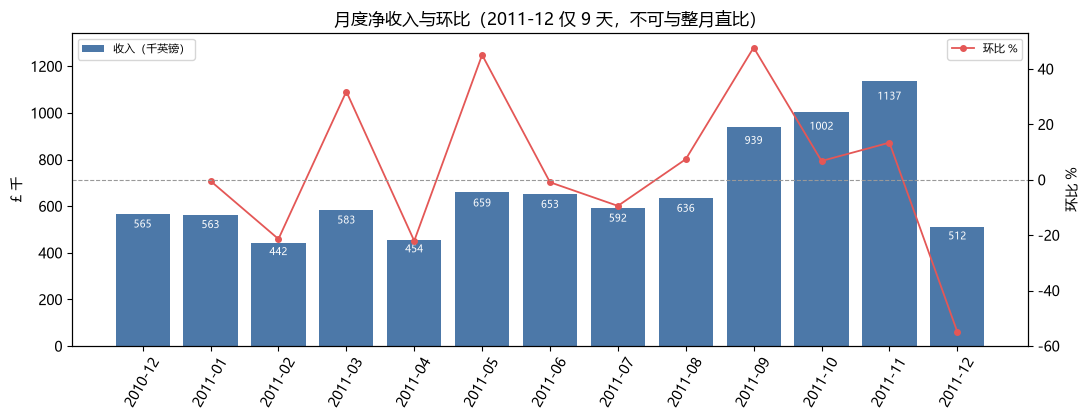

In [51]:
fig, ax = plt.subplots(figsize=(11, 4.3))
x = np.arange(len(monthly))
ax.bar(x, monthly['收入'] / 1000, color='#4C78A8', label='收入（千英镑）')
for i, v in enumerate(monthly['收入'] / 1000):
    ax.text(i, v * 0.96, f'{v:.0f}', ha='center', va='top', fontsize=7, color='white')
ax.set_xticks(x)
ax.set_xticklabels(monthly.index.astype(str), rotation=60)
ax.set_ylabel('£ 千')
ax.set_ylim(0, monthly['收入'].max() / 1000 * 1.18)
ax.set_title('月度净收入与环比（2011-12 仅 9 天，不可与整月直比）')

ax2 = ax.twinx()
ax2.plot(x, monthly['环比%'], color='#E45756', marker='o', ms=4, lw=1.3, label='环比 %')
ax2.axhline(0, color='#999', lw=0.8, ls='--')
ax2.set_ylabel('环比 %')
ax.legend(loc='upper left', fontsize=8)
ax2.legend(loc='upper right', fontsize=8)
plt.tight_layout()
plt.show()

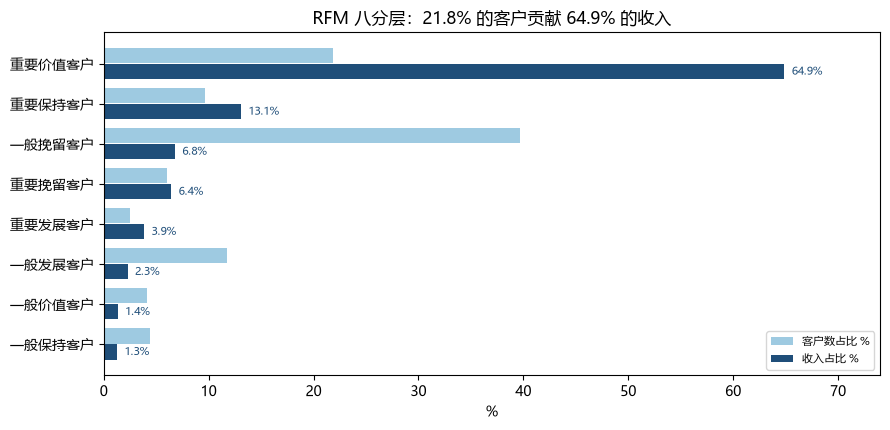

In [52]:
order = segment.index[::-1]
y = np.arange(len(order))
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.barh(y + 0.2, segment.loc[order, '客户占比%'], height=0.38, color='#9ECAE1', label='客户数占比 %')
ax.barh(y - 0.2, segment.loc[order, '收入占比%'], height=0.38, color='#1F4E79', label='收入占比 %')
for i, v in enumerate(segment.loc[order, '收入占比%']):
    ax.text(v + 0.7, i - 0.2, f'{v:.1f}%', va='center', fontsize=8, color='#1F4E79')
ax.set_yticks(y)
ax.set_yticklabels(order)
ax.set_xlabel('%')
ax.set_xlim(0, 74)
ax.set_title('RFM 八分层：21.8% 的客户贡献 64.9% 的收入')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

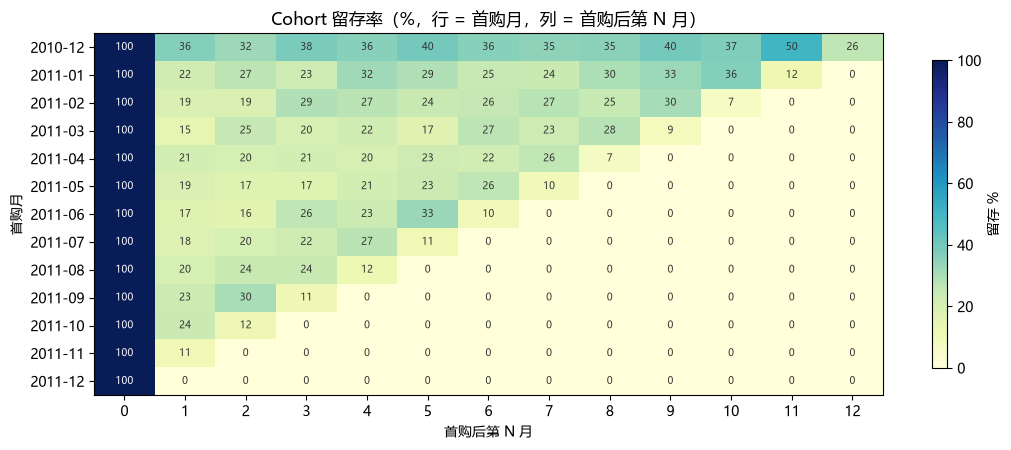

In [53]:
data = retention.iloc[:, :13]
fig, ax = plt.subplots(figsize=(11, 4.6))
im = ax.imshow(data.values, cmap='YlGnBu', vmin=0, vmax=100, aspect='auto')
ax.set_xticks(range(data.shape[1]))
ax.set_xticklabels(data.columns)
ax.set_yticks(range(data.shape[0]))
ax.set_yticklabels([str(i) for i in data.index])
for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        v = data.values[i, j]
        ax.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=7,
                color='white' if v > 55 else '#333333')
ax.set_title('Cohort 留存率（%，行 = 首购月，列 = 首购后第 N 月）')
ax.set_xlabel('首购后第 N 月')
ax.set_ylabel('首购月')
fig.colorbar(im, ax=ax, shrink=0.85, label='留存 %')
plt.tight_layout()
plt.show()

## 自检与计分（运行本格）

不用改这一格。它按 T1–T12 的验收点检查你定义的变量，给出得分。
未完成的题会显示 ✗，不会中断。

In [54]:
CHECKS = [
    ('T1 读取与体检（5 分）', 5,
     lambda: n_rows == 541909 and n_cols == 8 and abs(mem_mb - 160.7) < 3),
    ('T2 缺失值（5 分）', 5,
     lambda: int(miss.loc['Customer ID', '缺失数']) == 135080),
    ('T3 退货分析（10 分）', 10,
     lambda: cancel_rows == 9288 and abs(return_rate - 8.41) < 0.05),
    ('T4 重复行（5 分）', 5,
     lambda: dup_rows == 5268 and len(df_dedup) == 541909 - 5268),
    ('T5 派生列（10 分）', 10,
     lambda: {'Revenue', 'Year', 'Month', 'Weekday', 'Hour'} <= set(df.columns)
             and bool((df['Revenue'] == df['Quantity'] * df['UnitPrice']).all())),
    ('T6 清洗流水线（10 分）', 10,
     lambda: len(clean) == 391150 and abs(clean['Revenue'].sum() - 8737228.0) < 1),
    ('T7 月度收入（10 分）', 10,
     lambda: str(best_month).startswith('2011-11')
             and abs(monthly['收入'].sum() - 8737228.0) < 1),
    ('T8 国家透视（10 分）', 10,
     lambda: len(country_share) == 37 and abs(country_share.sum() - 100) < 0.5),
    ('T9 Top 商品（10 分）', 10,
     lambda: len(top_rev) == 10 and len(top_qty) == 10
             and str(top_rev.index[0]) == '23843'),
    ('T10 RFM 分层（15 分）', 15,
     lambda: abs(segment['客户数'].sum() - 4334) < 1
             and abs(segment['收入占比%'].sum() - 100) < 0.5),
    ('T11 Cohort 留存（5 分）', 5,
     lambda: len(retention) >= 10
             and bool((retention.iloc[:, 0] - 100).abs().max() < 0.01)),
    ('T12 向量化性能（5 分）', 5,
     lambda: t_fast < t_slow and t_slow / max(t_fast, 1e-6) > 10),
]

got = ok_count = 0
for name, pts, fn in CHECKS:
    try:
        ok = bool(fn())
    except Exception:
        ok = False
    got += pts if ok else 0
    ok_count += int(ok)
    print(('✔' if ok else '✗'), f'{name:<20}', f'+{pts}' if ok else '0')

print('-' * 46)
print(f'通过 {ok_count}/{len(CHECKS)} 题，得分 {got}/100')

✗ T1 读取与体检（5 分）        0
✔ T2 缺失值（5 分）          +5
✔ T3 退货分析（10 分）        +10
✔ T4 重复行（5 分）          +5
✔ T5 派生列（10 分）         +10
✔ T6 清洗流水线（10 分）       +10
✔ T7 月度收入（10 分）        +10
✔ T8 国家透视（10 分）        +10
✔ T9 Top 商品（10 分）      +10
✔ T10 RFM 分层（15 分）     +15
✔ T11 Cohort 留存（5 分）   +5
✔ T12 向量化性能（5 分）       +5
----------------------------------------------
通过 11/12 题，得分 95/100


## 我的三句话结论

用老板听得懂的话，写下三个答案（每句不超过 40 字）：

1. **生意怎么样**：全年做了 1,024.7 万英镑，9–11 月是旺季，11 月最好、2 月最淡。
2. **钱是哪些客户贡献的**：4,334 个客户里，947 个核心客户贡献 65%，资源优先给他们。
3. **货卖得怎么样**：最赚钱是纸艺小鸟；销量前十只有 6 个进金额前十，别按销量补货。

> 背后的三个数字：净营收 £8,737,228（含游客 £10,246,821）；重要价值客户 947 人 / 收入占比 64.89%；23843 销售额 £168,470。

---

**数据来源**：Chen, D. (2015). *Online Retail* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33

**方法参考**：Chen, D., Sain, S. L., & Guo, K. (2012). Data mining for the online retail industry: A case study of RFM model-based customer segmentation using data mining. *Journal of Database Marketing & Customer Strategy Management*, 19(3), 197–208.

**工具**：pandas（McKinney, 2010），NumPy（Harris et al., 2020）。

## 提交

1. 把整个 notebook **从头运行一遍**，确认最后一格打印出得分；
2. 另存为 `组长的学号-组长的姓名.ipynb`（例：`20230101-张三.ipynb`）；
3. 发送到 **20734980@qq.com**，邮件主题：`学号-姓名-pandas实验`；
4. 截止时间：**上课当天晚 23:00**。

> 每组只交一份，由组长提交。文件名不对或逾期，按未交处理。